## Lab 3: Asking statistical questions

In [2]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

## Problem 1

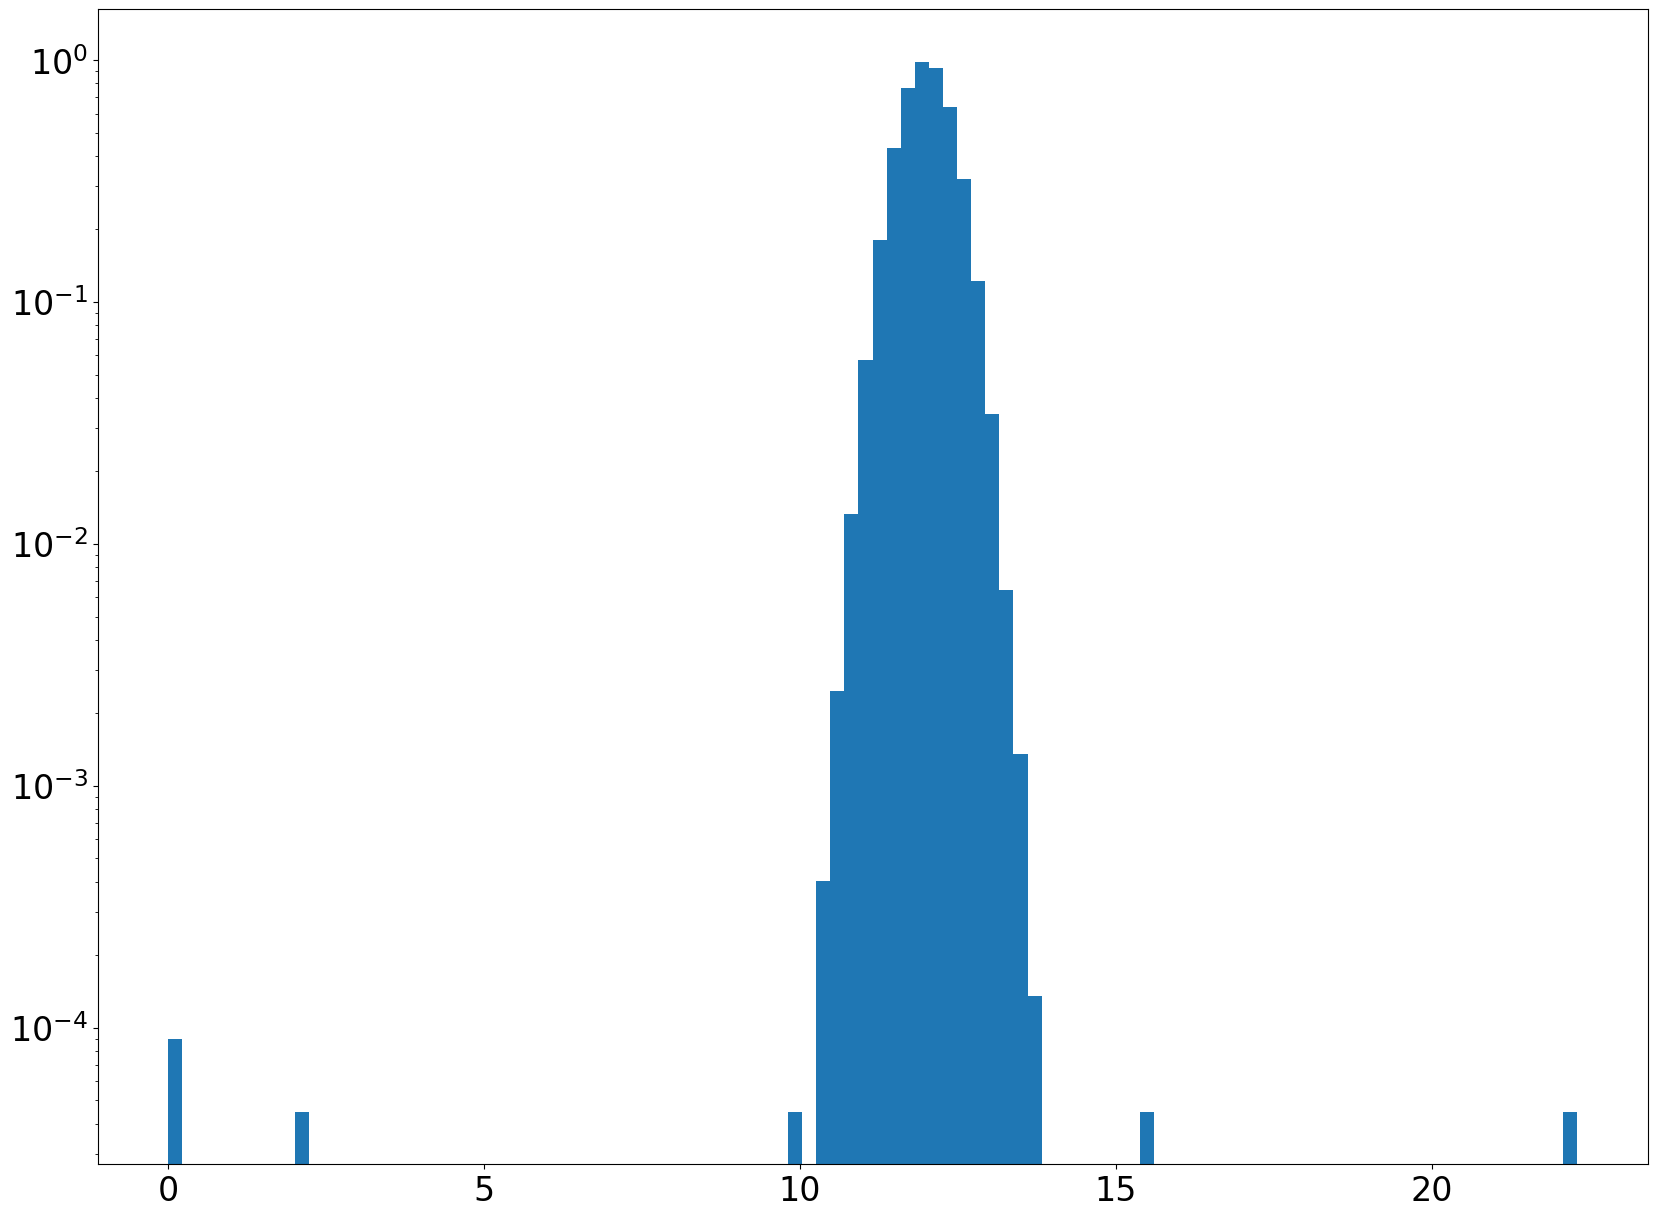

In [46]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

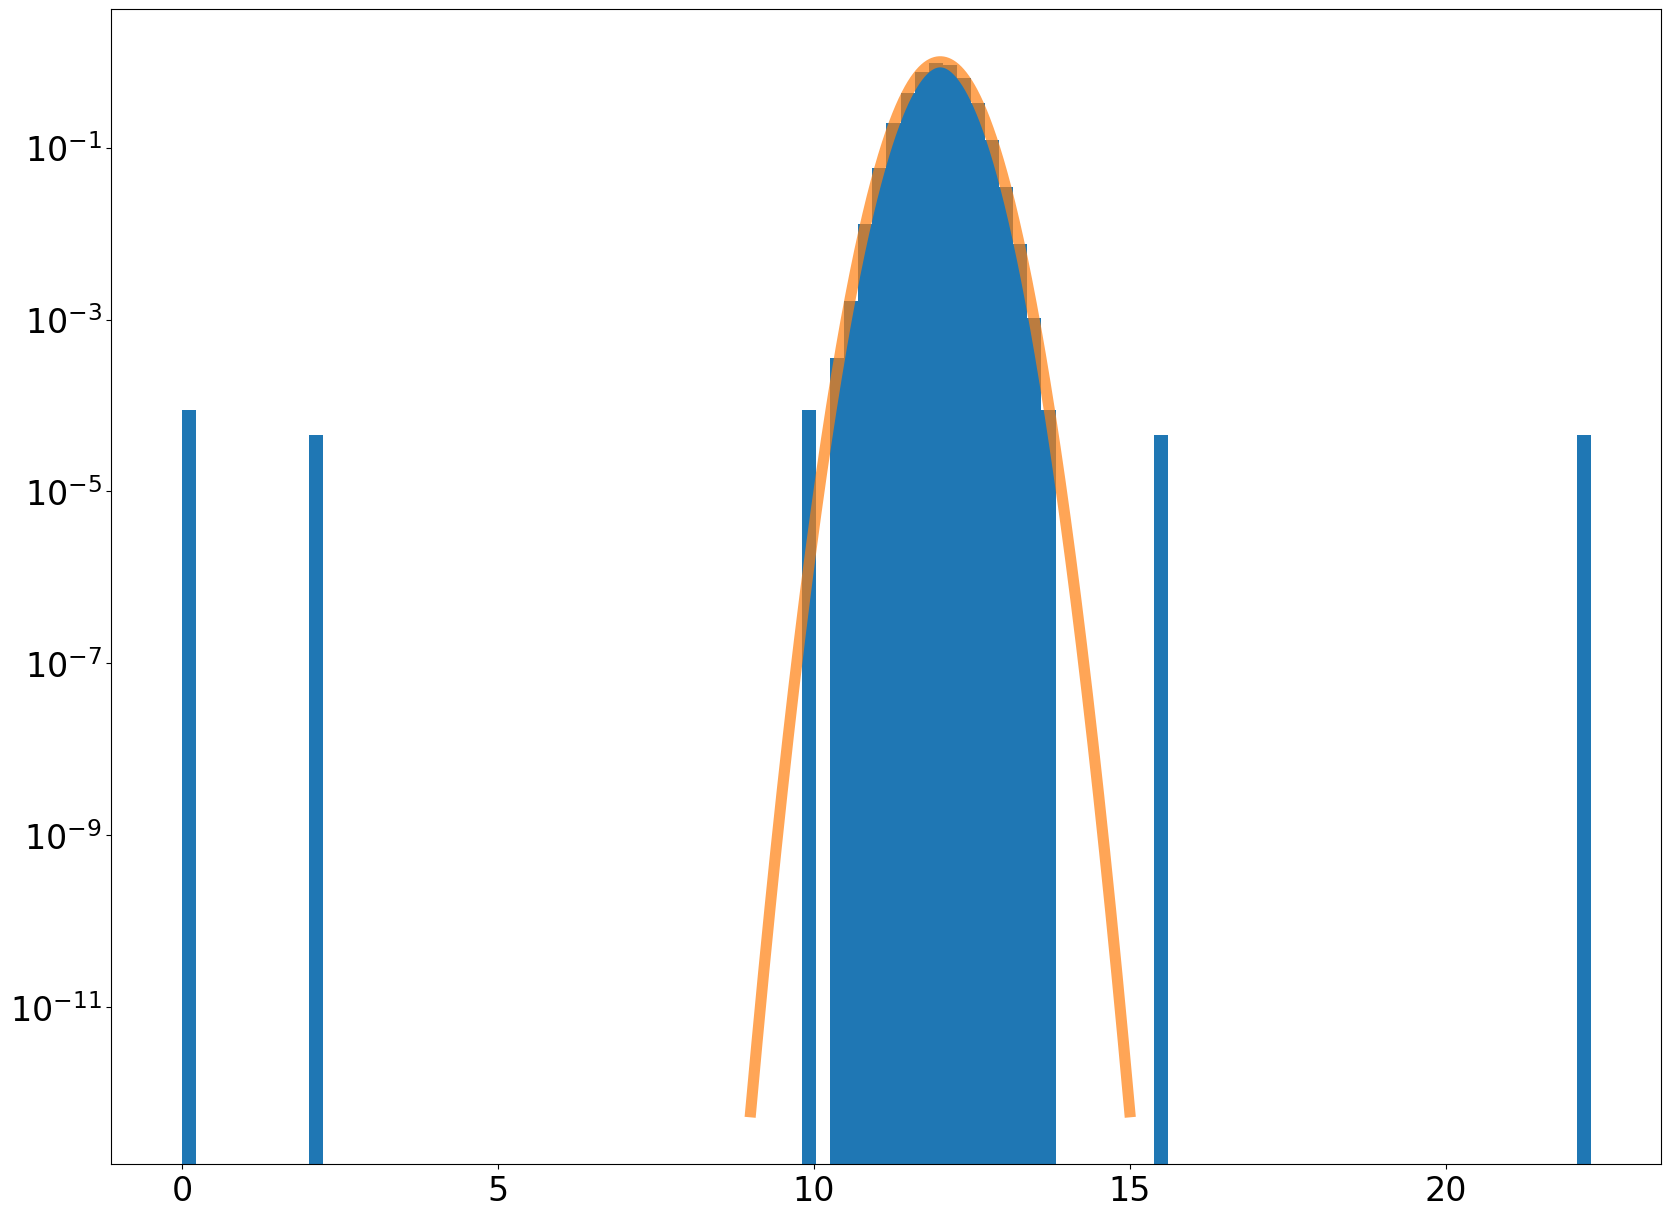

In [7]:
## These lines plot a normal distribution with mu = 12 and sigma = .4, as well as 8 additional points of data.
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')

## these additional lines plot a Gaussian curve overlaid highlighting the distant outliers
x = np.linspace(9,15,1000)
ax.plot(x,stats.norm.pdf(x, loc = 12, scale = 0.4),linewidth = 8,alpha = 0.7)
plt.show()

## Question 1.1: How do we identify and excise the bad data from our overall data set? 
#### Our overall set is mostly defined as a normal distribution with central value 12 and sigma value .4. In total, it is that distribution + 8 additional points.
#### Our plan is to identify which data points fall outside of 5 sigma towards either side, and remove them from the data set.
#### 5 sigma value = 5*.4 = 2. All data within that 12 +- (5sigma), is acceptable.
#### 

5 sigma value equals 2.0
Data above 14.0 to be discarded.
Data below 10.0 to be discarded.
The new data set includes 100003 points
These 5 data points were cut: [0, 0, 2.1, 15.6, 22.3]


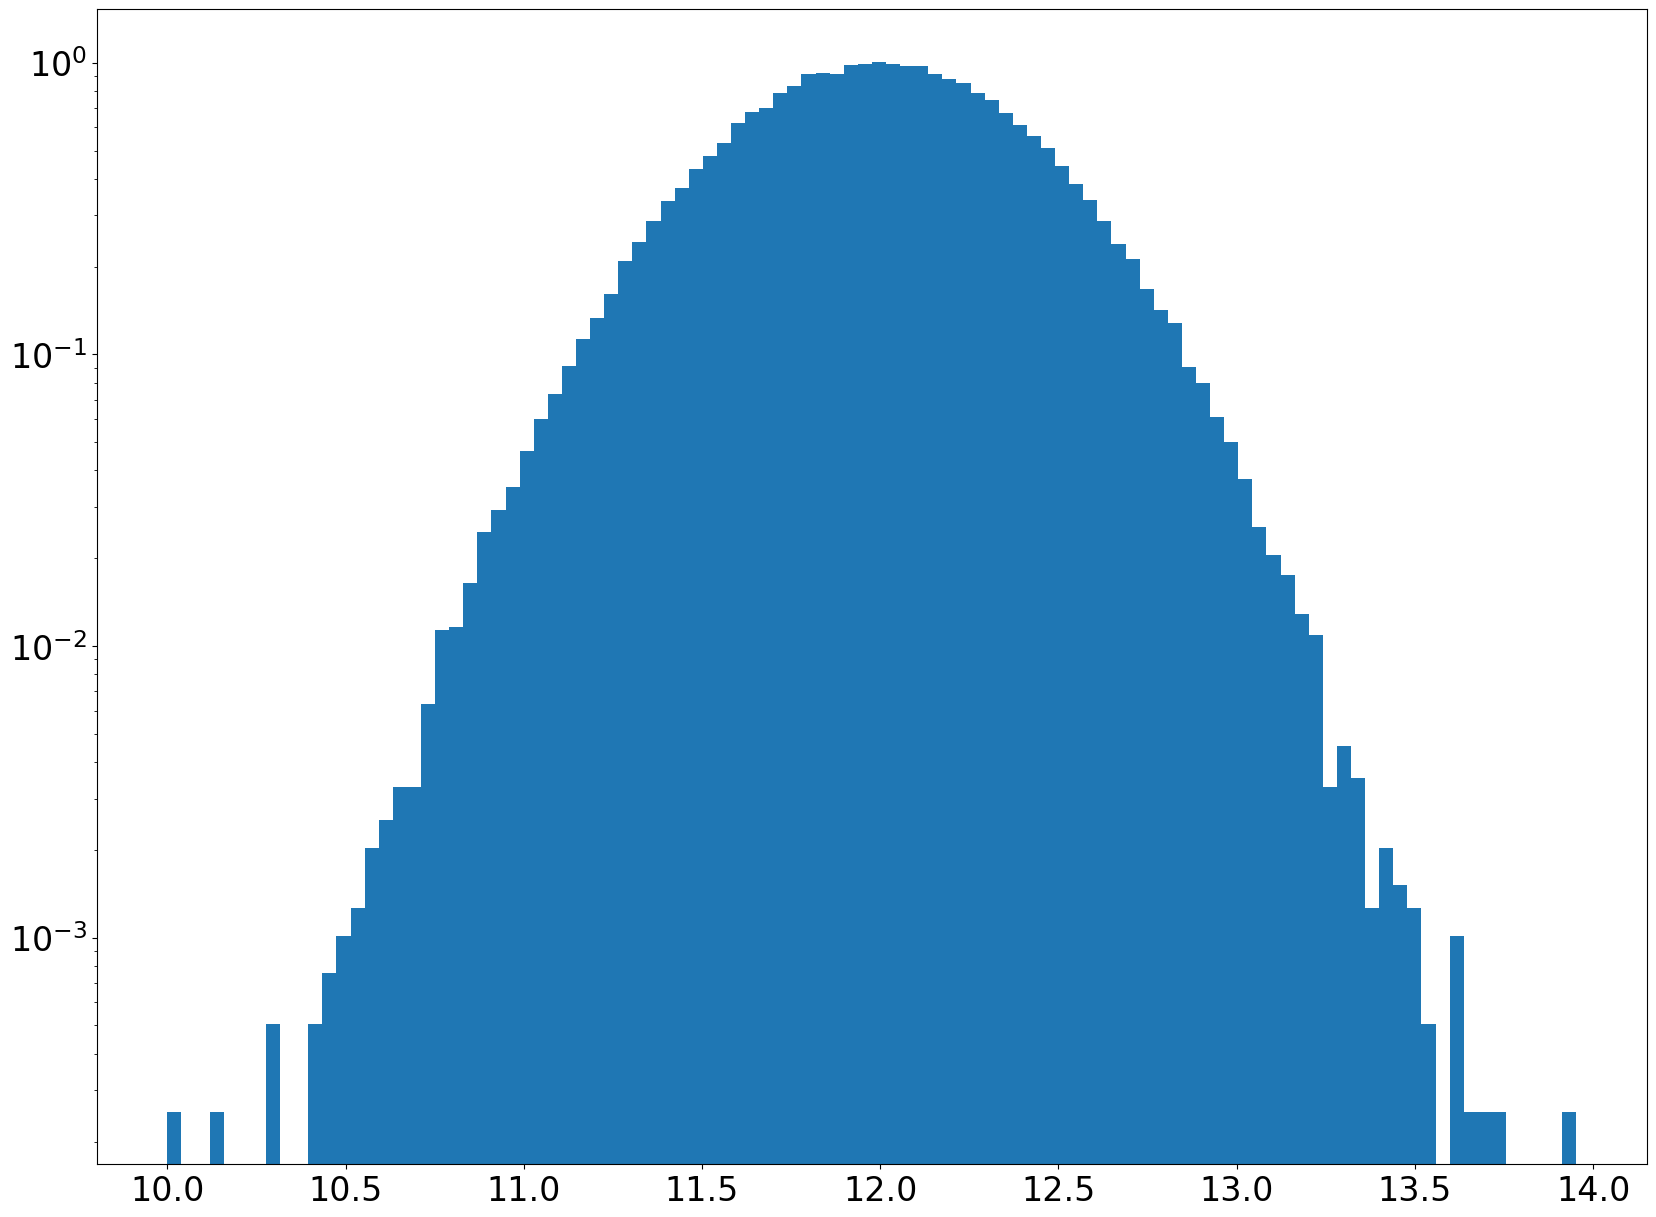

In [41]:
#Data characterstics
mu = 12
sigma = .4
print('5 sigma value equals', 5*sigma) 

#original data
d = np.append(stats.norm.rvs(loc = mu, scale = sigma, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])

#define 5sigma high cutoff point
high_cutoff = stats.norm.isf(sigma_cutoff_probability, loc= mu, scale = sigma)
print('Data above', high_cutoff, 'to be discarded.')

#define 5sigma low cutoff - which function does this???
lower_cutoff = mu - (5 * sigma) 
print('Data below', lower_cutoff, 'to be discarded.')

#define restricted data set
accepted_d = d[
    (d >= lower_cutoff) & (d <= high_cutoff)
]

# plot the restricted data set
fig, ax = plt.subplots(1, 1)
ax.hist(accepted_d, 100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')

#find the size of the restricted data set
accepted_d_size = len(accepted_d)
print('The new data set includes', accepted_d_size, 'points') 

#setting up truth table
#rejected data 
rejected = [0, 0, 2.1, 15.6, 22.3]
print('These 5 data points were cut:', rejected)

# I seriously do not know how to program this test or build the truth table. I regret doing Homweork 3 by hand - clearly it would have been valuable to have the truth table method on hand

In [42]:
# Problem 1.B
## The number of ommissions (false negatives) increases significantly as your statistical threshhold approaches your location factor.
## The wider your threshhold, the less good data you throw out. I think the number of ommissions is not predictable.
# Problem 1.C
## There are commissions - my simple cutoff method allowed 3 data points in. Commissions are unavoidable! Applyting too strict a threshold will remove much more good data than it does bad data.

## Problem 2

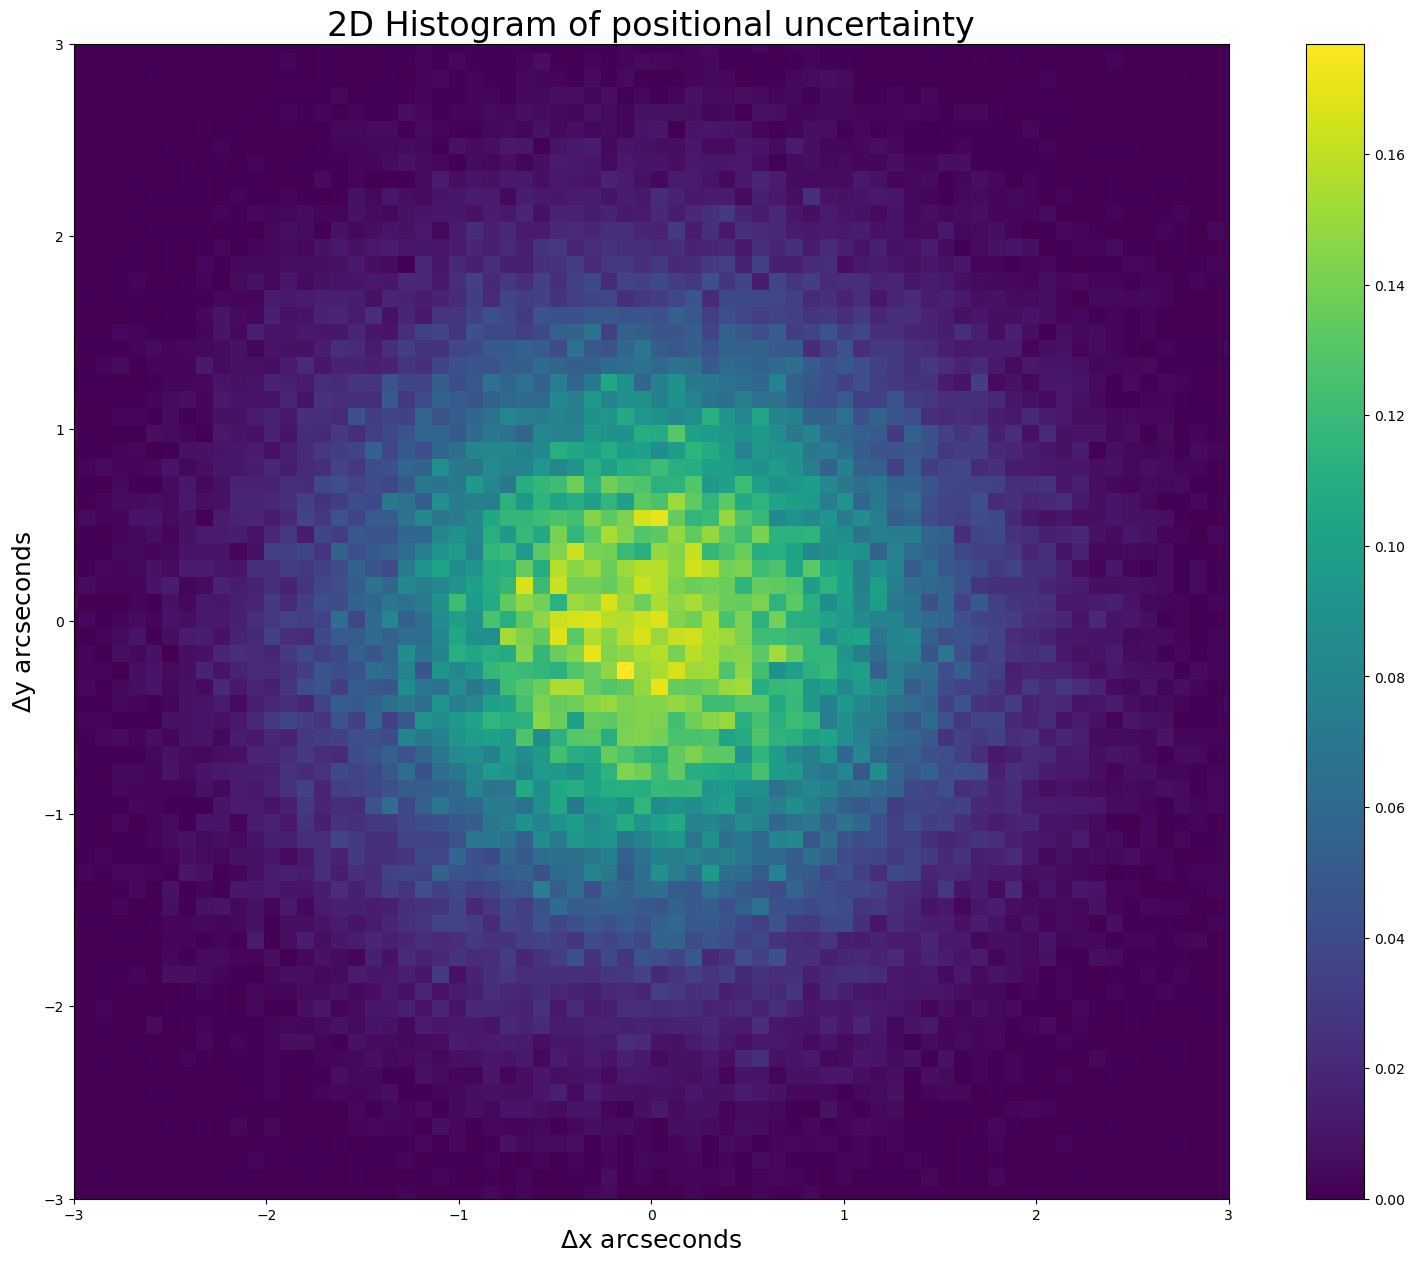

In [45]:
# 2-Dimensional data and plot
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel(r"$\Delta$y arcseconds", fontsize = 18)
plt.xlabel(r"$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

In [53]:
## Problem 2.1 What is the likelihood that the pdf of the magnitude of the 2D Gaussian is greater than 5 sigma?
## 2D Gaussian magnitude -> Rayleigh

## Problem 2.2 Integrate the normal distribution from positive infinity to 5 sigma to find the probability
prob_sigma_5 = stats.norm.sf(5, 0, 1)
print(prob_sigma_5)
print('The probability of 5 sigma is', prob_sigma_5)

length_5_sigma = stats.rayleigh.isf(prob_sigma_5, 0, 1)
print('A 5 sigma detection would correspond to a distance of', length_5_sigma, 'arceseconds.')

2.866515718791933e-07
The probability of 5 sigma is 2.866515718791933e-07
A 5 sigma detection would correspond to a distance of 5.489079776062419 arceseconds.


## Problem 3
#### As we discussed in class, one of the key backgrounds for gamma-ray telescopes are cosmic rays. Cosmic rays are charged particles—usually protons or electrons but can include atomic nuclei such a alpha particles (helium) or iron. Because of their charge cosmic rays spiral in the magnetic field of the galaxy. From the perspective of the Earth they appear to be coming uniformly from all directions like a high energy gas, and the direction the cosmic ray is travelling when it reaches the Earth tells us nothing about where it came from because we don't know what tortured path it has taken through the galaxy to reach us. However, at trillion electron volt energies and above, the spiral loops are fairly big and the sun and the moon will block cosmic rays. This means the sun and the moon appear as holes in the cosmic ray sky (cosmic rays from that direction are absorbed).

#### Assume in a moon sized patch on the sky we normally have a cosmic ray rate of 1 cosmic ray per minute (arrivals are random in time). If we can observe where the moon is for 8 hours per night (not too close to the horizon) and we observe for 15 days and see 6800 cosmic rays, what is the signficance of our moon shadow detection?

In [58]:
# Problem 3.1 In a certain direction, we observed slightly fewer than the expected the number of expected cosmic rays over 15 days of night-time observations. 
# How likely is it that we were looking at the moon? What sigma does our 
# 21,600 minutes in 15 days, 7200 minutes in 15 days worth of night-time observations - should be 7200 rays detected
# Only 6800 rays were detected. Fewer but not too many fewer. 
# Prediction: it's not likely that we were looking at the moon. Sigma should be low

# Poissonian distribution for rates
mu = 7200

#background, expected distribution
background = stats.poisson.pmf(7200, mu, loc=0)

#likelihood of detecting only 6800 rays
likelihood = stats.poisson.sf(6800, mu, loc=0)
print(likelihood)

#sigma
sigma = stats.norm.ppf(likelihood)
print(sigma)

0.9999989866719816
4.750747965778662
